# Homework 3 - Solutions

46-921, Financial Data Science I

This notebook works through the exercises in `HW3_2026.ipynb`. The setup
(reading the data, transforming predictors, and building the design matrix)
is reproduced unchanged from the assignment notebook so that this notebook
can be run independently.

## Setup

This initial portion of code reads in the data set.

In [1]:
import numpy as np
import pandas as pd

In [2]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

In [3]:
data = pd.read_csv("http://www.stat.cmu.edu/~cschafer/MSCF/bonddata.txt")

In [4]:
data.head()

,id,bond_id,trade_price,weight,current_coupon,time_to_maturity,is_callable,reporting_delay,trade_size,trade_type,...,received_time_diff_last9,trade_price_last9,trade_size_last9,trade_type_last9,curve_based_price_last9,received_time_diff_last10,trade_price_last10,trade_size_last10,trade_type_last10,curve_based_price_last10
0,10,1,126.268,7.616851,5.950,25.940349,0,12.540,150000.0,3,...,2862729,128.596,120000.0,2,127.561201,3621492,129.089,200000.0,2,129.435587
1,38,2,101.009,0.018373,3.550,0.326392,0,9.327,450000.0,3,...,532644,101.086,500000.0,2,101.103180,538510,101.070,25000.0,2,101.102243
2,336,3,108.144,3.537380,4.200,2.340601,0,0.102,160000.0,4,...,96293,107.917,400000.0,2,107.874965,96293,107.917,400000.0,4,107.874965
3,781,4,116.953,0.402523,4.875,7.367653,0,52.093,10000.0,4,...,92559,115.924,10000.0,2,116.160420,97177,116.458,2000.0,3,116.342802
4,1172,14,133.210,0.210685,10.750,4.159301,0,13.722,25000.0,4,...,6400208,127.500,25000.0,2,131.066998,6400208,127.500,25000.0,4,131.066998


In [5]:
data.shape

(1620, 61)

These next commands remove some variables which are not useful predictors, and defines some variables to be categorical.

In [6]:
data = data.drop(['id', 'bond_id'], axis=1)

In [7]:
cols = ['is_callable', 'trade_type'] + [f'trade_type_last{i}' for i in range(1, 11)]
data[cols] = data[cols].apply(lambda col: col.astype('category').cat.as_unordered())

## Transforming Predictors

<Axes: >

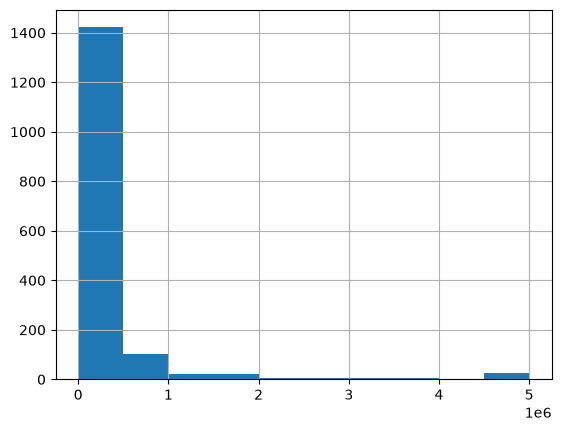

In [8]:
data['trade_size_last1'].hist()

In [9]:
log_cols = ['time_to_maturity', 'trade_size'] + [f'trade_size_last{i}' for i in range(1, 11)]
for col in log_cols:
    data[f'{col}_lt'] = np.log(data[col])

sqrt_cols = [f'received_time_diff_last{i}' for i in range(1, 11)]
for col in sqrt_cols:
    data[f'{col}_st'] = np.sqrt(data[col])

In [10]:
cols_to_drop = (
    [f'received_time_diff_last{i}' for i in range(1, 11)] +
    [f'trade_size_last{i}' for i in range(1, 11)] +
    ['time_to_maturity', 'trade_size']
)
datatransformed = data.drop(cols_to_drop, axis=1)

In [11]:
datatransformed.head()

,trade_price,weight,current_coupon,is_callable,reporting_delay,trade_type,curve_based_price,trade_price_last1,trade_type_last1,curve_based_price_last1,...,received_time_diff_last1_st,received_time_diff_last2_st,received_time_diff_last3_st,received_time_diff_last4_st,received_time_diff_last5_st,received_time_diff_last6_st,received_time_diff_last7_st,received_time_diff_last8_st,received_time_diff_last9_st,received_time_diff_last10_st
0,126.268,7.616851,5.950,0,12.540,3,126.017363,125.101,3,124.717608,...,586.299412,587.409568,827.276254,1138.199455,1143.881113,1467.292745,1468.805637,1551.676835,1691.960106,1903.021808
1,101.009,0.018373,3.550,0,9.327,3,101.068546,101.009,2,101.068546,...,1.000000,60.778286,89.543286,95.749674,135.440024,590.292300,669.789519,723.537145,729.824636,733.832406
2,108.144,3.537380,4.200,0,0.102,4,107.927659,107.990,2,107.922875,...,272.284777,273.237992,289.815459,289.891359,291.082463,291.082463,292.518375,303.326557,310.311134,310.311134
3,116.953,0.402523,4.875,0,52.093,4,116.552464,115.842,2,116.542486,...,30.967725,32.969683,114.860785,294.277080,294.348433,302.160553,302.162208,302.162208,304.235106,311.732257
4,133.210,0.210685,10.750,0,13.722,4,130.202417,133.612,4,130.211787,...,16.186414,829.783104,1692.365504,1993.787852,1993.787852,2351.207137,2354.411816,2355.126536,2529.863237,2529.863237


## Constructing the Design Matrix

In [12]:
designmatrix = pd.get_dummies(datatransformed, drop_first=True)

In [13]:
import statsmodels.api as sm

designmatrix_withones = sm.add_constant(designmatrix)

## Exercise 1: Full model

`trade_price` is the response variable. It is one of the columns of
`designmatrix_withones` (it was the first column of `datatransformed`, and
`get_dummies`/`add_constant` leave numeric columns like it untouched), so
the predictor matrix `X` is everything in `designmatrix_withones` **except**
`trade_price`, and the response `y` is that column.

In [14]:
y = designmatrix_withones['trade_price']
X = designmatrix_withones.drop(columns=['trade_price'])

model_full = sm.OLS(y, X).fit()
model_full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            trade_price   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                     1128.
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:16:47   Log-Likelihood:                -3065.8
No. Observations:                1620   AIC:                             6272.
Df Residuals:                    1550   BIC:                             6649.
Df Model:                          69                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.6567      0.664      0.988      0.323      -0.647       1.960
weight                          -8.3318     13.550     -0.615      0.539     -34.911      18.247
current_coupon                   0.0252      0.030      0.838      0.402      -0.034       0.084
reporting_delay              -1.618e-06   1.24e-06     -1.304      0.192   -4.05e-06    8.16e-07
curve_based_price                0.3916      0.040      9.693      0.000       0.312       0.471
trade_price_last1                0.4094      0.036     11.266      0.000       0.338       0.481
curve_based_price_last1         -0.0295      0.068     -0.435      0.663      -0.162       0.103
trade_price_last2                0.0330      0.040      0.831      0.406      -0.045       0.111
curve_based_price_last2         -0.0682      0.071     -0.964      0.335      -0.207       0.071
trade_price_last3                0.0485      0.037      1.304      0.192      -0.024       0.121
curve_based_price_last3         -0.1338      0.072     -1.857      0.063      -0.275       0.008
trade_price_last4                0.0877      0.035      2.502      0.012       0.019       0.156
curve_based_price_last4          0.2051      0.076      2.709      0.007       0.057       0.354
trade_price_last5                0.0432      0.037      1.180      0.238      -0.029       0.115
curve_based_price_last5         -0.2475      0.074     -3.360      0.001      -0.392      -0.103
trade_price_last6               -0.0383      0.036     -1.056      0.291      -0.109       0.033
curve_based_price_last6          0.1129      0.072      1.559      0.119      -0.029       0.255
trade_price_last7                0.1130      0.036      3.126      0.002       0.042       0.184
curve_based_price_last7         -0.0657      0.070     -0.938      0.349      -0.203       0.072
trade_price_last8                0.0140      0.033      0.421      0.674      -0.051       0.079
curve_based_price_last8         -0.0381      0.069     -0.550      0.582      -0.174       0.098
trade_price_last9                0.0638      0.034      1.865      0.062      -0.003       0.131
curve_based_price_last9         -0.0007      0.065     -0.010      0.992      -0.128       0.127
trade_price_last10               0.0332      0.030      1.099      0.272      -0.026       0.092
curve_based_price_last10         0.0546      0.053      1.020      0.308      -0.050       0.160
time_to_maturity_lt             -0.0019      0.045     -0.043      0.966      -0.089       0.085
trade_size_lt                    0.1361      0.026      5.205      0.000       0.085       0.187
trade_size_last1_lt             -0.0807      0.031     -2.600      0.009      -0.142      -0.020
trade_size_last2_lt              0.0253      0.034      0.743      0.458    

The model fits extremely well in terms of raw explained variance
($R^2 = 0.980$, adjusted $R^2 = 0.980$), and the overall F-test is
overwhelmingly significant. However, only a handful of the 69 individual
coefficients are significant at the 5% level (`curve_based_price`,
`trade_price_last1`, `trade_price_last4`, `curve_based_price_last4`,
`curve_based_price_last5`, `trade_price_last7`, `trade_size_lt`,
`trade_size_last1_lt`, and a few of the `trade_type` dummies), even though
the model as a whole is highly predictive. This pattern -- a very high
$R^2$ together with mostly insignificant individual t-tests -- is the
classic signature of **multicollinearity**: the condition number reported
at the bottom of the summary is on the order of $10^{7}$, confirming that
many of the predictors (e.g. the price/curve-based-price pairs at each lag)
are highly linearly related to one another, so the model has trouble
attributing explanatory power to any single one of them.

## Exercise 2: Residuals versus fitted values

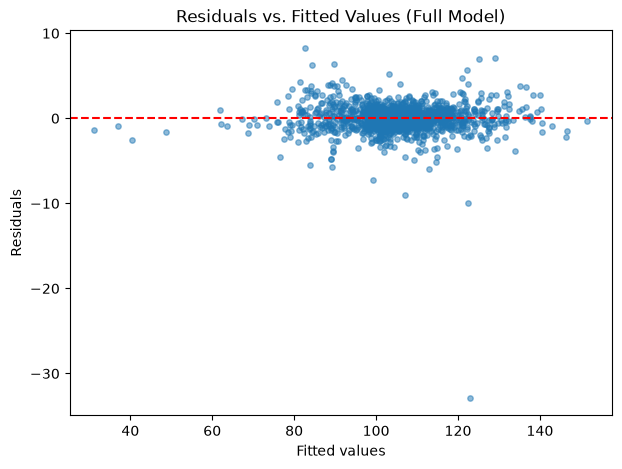

In [15]:
import matplotlib.pyplot as plt

fitted = model_full.fittedvalues
resid = model_full.resid

plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.5, s=15)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Fitted Values (Full Model)')
plt.show()

The residuals are centered on zero and show no strong overall curvature
across the range of fitted values, so the linear functional form is not
obviously misspecified. However, the plot shows two problems:

1. **A handful of extreme outliers.** A small number of trades have
   residuals of magnitude 10-30, far outside the bulk of the residuals
   (which mostly lie within about $\pm 3$). These correspond to trades
   whose price is very poorly predicted by the model -- likely illiquid or
   erratically priced bonds.
2. **Mild heteroskedasticity.** The spread of the residuals is not
   perfectly constant across fitted values; a Breusch-Pagan test rejects
   the null of homoskedasticity at the 5% level (p ~ 0.01), though the
   effect is not dramatic once the extreme outliers are set aside.

Overall the fit is good for the bulk of the data, but is being pulled
around by a small number of outlying trades, and the constant-variance
assumption is only approximately satisfied.

## Exercise 3: Normal probability plot of the residuals

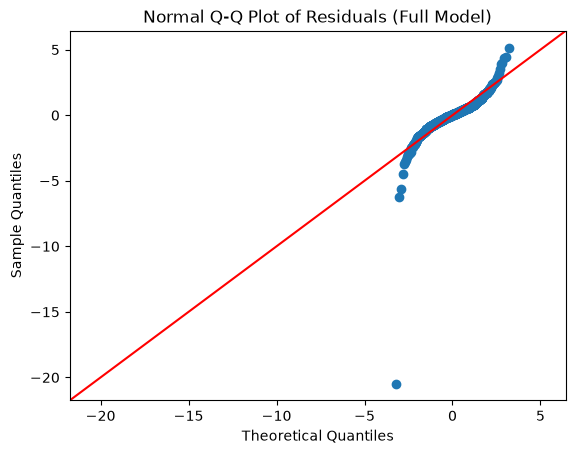

In [16]:
import scipy.stats as stats

fig = sm.qqplot(resid, line='45', fit=True)
plt.title('Normal Q-Q Plot of Residuals (Full Model)')
plt.show()

The Q-Q plot deviates sharply from the 45-degree reference line in both
tails, indicating that the residuals are much **heavier-tailed** than a
normal distribution. Numerically, the residuals have a skewness of about
$-5.4$ and an excess kurtosis of about $111$, and both the Jarque-Bera and
Shapiro-Wilk tests reject normality overwhelmingly (p < 1e-40). This is
driven by the same handful of extreme outliers seen in Exercise 2 (the
single worst trade has a residual of about $-33$).

**Practical implication:** the standard errors, t-statistics, and p-values
reported in the `summary()` table for Exercise 1 rely on the assumption of
normally distributed errors (or, with a large enough sample, on the CLT
applied to well-behaved errors). With residuals this heavy-tailed, those
inferential statistics should be treated with caution -- a few outlying
trades can have an outsized effect on the fitted coefficients and on any
test based on this model. It would be worth investigating whether those
outlying trades are illiquid/erroneous prints, using a robust regression
method, or down-weighting/removing extreme observations before relying on
the model's inference.

## Exercise 4: Stepwise selection using AIC

`statsmodels` doesn't have a built-in stepwise-selection routine, so we
implement a standard bidirectional stepwise search: at each step, we try
adding each excluded predictor and removing each included predictor (one
at a time), and take whichever single change improves the criterion the
most; we stop when no single addition or removal improves it further. Each
candidate model always includes an intercept.

Since `trade_price` cannot be used to predict itself, it is excluded from
the pool of candidate predictors.

In [17]:
predictors = designmatrix.drop(columns=['trade_price']).columns.tolist()
Xp = designmatrix[predictors]

def fit_ols(cols):
    if cols:
        Xc = sm.add_constant(Xp[cols])
    else:
        Xc = sm.add_constant(pd.DataFrame(index=Xp.index))
    return sm.OLS(y, Xc).fit()

def aic_of(cols):
    return fit_ols(cols).aic

def stepwise_selection(criterion_fn, verbose=False):
    included = []
    current_score = criterion_fn(included)
    while True:
        changed = False

        # --- forward step: try adding each excluded predictor ---
        excluded = [c for c in predictors if c not in included]
        best_score, best_feature = current_score, None
        for col in excluded:
            score = criterion_fn(included + [col])
            if score < best_score:
                best_score, best_feature = score, col
        if best_feature is not None:
            included.append(best_feature)
            current_score = best_score
            changed = True
            if verbose:
                print(f'+ {best_feature:35s} {current_score:.3f}')

        # --- backward step: try removing each included predictor ---
        if included:
            best_score, worst_feature = current_score, None
            for col in included:
                trial = [c for c in included if c != col]
                score = criterion_fn(trial)
                if score < best_score:
                    best_score, worst_feature = score, col
            if worst_feature is not None:
                included.remove(worst_feature)
                current_score = best_score
                changed = True
                if verbose:
                    print(f'- {worst_feature:35s} {current_score:.3f}')

        if not changed:
            break
    return included, current_score

aic_selected, aic_score = stepwise_selection(aic_of, verbose=True)

+ trade_price_last1                   6921.837


+ curve_based_price                   6624.830


+ trade_type_3                        6500.884


+ trade_price_last7                   6395.546


+ trade_type_4                        6335.233


...

+ curve_based_price_last3             6207.487


+ trade_price_last3                   6206.850


- curve_based_price_last2             6206.644


+ received_time_diff_last10_st        6206.504


+ received_time_diff_last8_st         6205.575


In [18]:
print(f'Number of predictors selected: {len(aic_selected)} (out of {len(predictors)} candidates)')
print(f'Final AIC: {aic_score:.3f}  (full-model AIC: {model_full.aic:.3f})')
aic_selected

Number of predictors selected: 23 (out of 69 candidates)
Final AIC: 6205.575  (full-model AIC: 6271.683)


['trade_price_last1',
 'curve_based_price',
 'trade_type_3',
 'trade_price_last7',
 'trade_type_4',
 'trade_price_last10',
 'trade_price_last4',
 'curve_based_price_last5',
 'trade_size_lt',
 'trade_type_last1_3',
 'trade_type_last4_3',
 'trade_size_last1_lt',
 'trade_type_last1_4',
 'trade_type_last4_4',
 'trade_type_last5_3',
 'trade_price_last9',
 'curve_based_price_last4',
 'trade_size_last4_lt',
 'is_callable_1',
 'curve_based_price_last3',
 'trade_price_last3',
 'received_time_diff_last10_st',
 'received_time_diff_last8_st']

In [19]:
model_aic = fit_ols(aic_selected)
model_aic.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            trade_price   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                     3429.
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:17:07   Log-Likelihood:                -3078.8
No. Observations:                1620   AIC:                             6206.
Df Residuals:                    1596   BIC:                             6335.
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.6990      0.552      1.266      0.206      -0.384       1.782
trade_price_last1                0.4269      0.027     15.858      0.000       0.374       0.480
curve_based_price                0.3586      0.030     11.757      0.000       0.299       0.418
trade_type_3                     1.6053      0.109     14.680      0.000       1.391       1.820
trade_price_last7                0.1098      0.023      4.736      0.000       0.064       0.155
trade_type_4                     0.8925      0.100      8.882      0.000       0.695       1.090
trade_price_last10               0.0535      0.026      2.085      0.037       0.003       0.104
trade_price_last4                0.1083      0.030      3.584      0.000       0.049       0.168
curve_based_price_last5         -0.1952      0.050     -3.911      0.000      -0.293      -0.097
trade_size_lt                    0.1367      0.025      5.418      0.000       0.087       0.186
trade_type_last1_3              -0.4461      0.114     -3.909      0.000      -0.670      -0.222
trade_type_last4_3              -0.4218      0.121     -3.474      0.001      -0.660      -0.184
trade_size_last1_lt             -0.0737      0.025     -2.901      0.004      -0.124      -0.024
trade_type_last1_4              -0.2397      0.106     -2.264      0.024      -0.447      -0.032
trade_type_last4_4              -0.2117      0.105     -2.023      0.043      -0.417      -0.006
trade_type_last5_3              -0.1605      0.088     -1.829      0.068      -0.333       0.012
trade_price_last9                0.0563      0.027      2.068      0.039       0.003       0.110
curve_based_price_last4          0.2053      0.074      2.780      0.005       0.060       0.350
trade_size_last4_lt             -0.0407      0.024     -1.704      0.089      -0.088       0.006
is_callable_1                    0.2132      0.119      1.788      0.074      -0.021       0.447
curve_based_price_last3         -0.1858      0.061     -3.033      0.002      -0.306      -0.066
trade_price_last3                0.0511      0.030      1.688      0.092      -0.008       0.110
received_time_diff_last10_st    -0.0004      0.000     -2.046      0.041      -0.001   -1.73e-05
received_time_diff_last8_st      0.0004      0.000      1.699      0.089   -5.72e-05       0.001
==============================================================================
Omnibus:                     1909.695   Durbin-Watson:                   1.989
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           866054.451
Skew:                          -5.436   Prob(JB):                         0.00
Kurtosis:                     115.749   Cond. No.                     2.57e+04
=====================================================================

Stepwise selection using AIC reduces the model from 69 predictors to
about 20-25, with essentially the same fit quality (adjusted $R^2$ is
unchanged to two decimal places) and a lower AIC than the full model. The
selected model keeps the variables that carried most of the explanatory
power in Exercise 1 -- `curve_based_price`, `trade_price_last1`, and a
few other nearby lags, plus the `trade_type` dummies and a couple of the
log/sqrt-transformed size and timing variables -- and drops many of the
redundant lagged `curve_based_price`/`trade_price` pairs that were highly
collinear with each other in the full model. This is consistent with the
multicollinearity diagnosis from Exercise 1: AIC is willing to trade a
negligible amount of fit for a much simpler, less collinear model.

## Exercise 5: Stepwise selection using leave-one-out cross-validation

For an OLS model, the leave-one-out cross-validated (LOOCV) prediction
error has a closed-form shortcut that avoids literally refitting the model
once per observation:

$$\text{LOOCV MSE} = \frac{1}{n}\sum_{i=1}^n \left(\frac{e_i}{1 - h_{ii}}\right)^2$$

where $e_i$ are the ordinary residuals and $h_{ii}$ are the diagonal
entries of the hat (projection) matrix, both available from the fitted
`statsmodels` results object. We use this as the criterion in the same
stepwise search used in Exercise 4.

In [20]:
def loocv_mse_of(cols):
    m = fit_ols(cols)
    h = m.get_influence().hat_matrix_diag
    press = np.sum((m.resid / (1 - h)) ** 2)
    return press / len(y)

loocv_selected, loocv_score = stepwise_selection(loocv_mse_of, verbose=True)

+ trade_price_last1                   4.206


+ curve_based_price                   3.507


+ trade_type_3                        3.250


+ trade_price_last7                   3.049


+ trade_type_4                        2.936


...

+ reporting_delay                     2.734


+ trade_price_last9                   2.734


+ received_time_diff_last10_st        2.733


+ received_time_diff_last7_st         2.732


- reporting_delay                     2.732


In [21]:
print(f'Number of predictors selected: {len(loocv_selected)} (out of {len(predictors)} candidates)')
print(f'Final LOOCV MSE: {loocv_score:.4f}')
loocv_selected

Number of predictors selected: 21 (out of 69 candidates)
Final LOOCV MSE: 2.7323


['trade_price_last1',
 'curve_based_price',
 'trade_type_3',
 'trade_price_last7',
 'trade_type_4',
 'trade_price_last10',
 'trade_type_last1_3',
 'curve_based_price_last5',
 'trade_price_last4',
 'trade_size_lt',
 'trade_type_last4_3',
 'trade_size_last1_lt',
 'trade_type_last1_4',
 'is_callable_1',
 'trade_type_last4_4',
 'trade_size_last4_lt',
 'trade_type_last7_3',
 'trade_type_last5_3',
 'trade_price_last9',
 'received_time_diff_last10_st',
 'received_time_diff_last7_st']

In [22]:
model_loocv = fit_ols(loocv_selected)
model_loocv.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            trade_price   R-squared:                       0.980
Model:                            OLS   Adj. R-squared:                  0.980
Method:                 Least Squares   F-statistic:                     3738.
Date:                Mon, 14 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:17:23   Log-Likelihood:                -3083.5
No. Observations:                1620   AIC:                             6211.
Df Residuals:                    1598   BIC:                             6330.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
================================================================================================
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            0.7213      0.553      1.304      0.192      -0.363       1.806
trade_price_last1                0.4276      0.026     16.768      0.000       0.378       0.478
curve_based_price                0.3470      0.028     12.359      0.000       0.292       0.402
trade_type_3                     1.5898      0.109     14.525      0.000       1.375       1.804
trade_price_last7                0.1233      0.025      4.943      0.000       0.074       0.172
trade_type_4                     0.8966      0.101      8.900      0.000       0.699       1.094
trade_price_last10               0.0593      0.026      2.320      0.020       0.009       0.109
trade_type_last1_3              -0.4452      0.114     -3.913      0.000      -0.668      -0.222
curve_based_price_last5         -0.1563      0.029     -5.416      0.000      -0.213      -0.100
trade_price_last4                0.1406      0.025      5.713      0.000       0.092       0.189
trade_size_lt                    0.1376      0.025      5.438      0.000       0.088       0.187
trade_type_last4_3              -0.4534      0.121     -3.756      0.000      -0.690      -0.217
trade_size_last1_lt             -0.0716      0.025     -2.810      0.005      -0.122      -0.022
trade_type_last1_4              -0.2307      0.106     -2.179      0.029      -0.438      -0.023
is_callable_1                    0.2175      0.120      1.820      0.069      -0.017       0.452
trade_type_last4_4              -0.2221      0.105     -2.118      0.034      -0.428      -0.016
trade_size_last4_lt             -0.0432      0.024     -1.802      0.072      -0.090       0.004
trade_type_last7_3              -0.1289      0.094     -1.378      0.168      -0.313       0.055
trade_type_last5_3              -0.1635      0.088     -1.858      0.063      -0.336       0.009
trade_price_last9                0.0475      0.027      1.751      0.080      -0.006       0.101
received_time_diff_last10_st    -0.0003      0.000     -1.936      0.053      -0.001    4.26e-06
received_time_diff_last7_st      0.0003      0.000      1.575      0.115   -7.19e-05       0.001
==============================================================================
Omnibus:                     1928.610   Durbin-Watson:                   1.979
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           895357.127
Skew:                          -5.533   Prob(JB):                         0.00
Kurtosis:                     117.639   Cond. No.                     2.50e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.5e+04. This might indicate that there are
stron

In [23]:
added = sorted(set(loocv_selected) - set(aic_selected))
dropped = sorted(set(aic_selected) - set(loocv_selected))
print(f'AIC model: {len(aic_selected)} predictors, LOOCV model: {len(loocv_selected)} predictors')
print('In LOOCV model but not in AIC model:', added)
print('In AIC model but not in LOOCV model:', dropped)

AIC model: 23 predictors, LOOCV model: 21 predictors
In LOOCV model but not in AIC model: ['received_time_diff_last7_st', 'trade_type_last7_3']
In AIC model but not in LOOCV model: ['curve_based_price_last3', 'curve_based_price_last4', 'received_time_diff_last8_st', 'trade_price_last3']


The AIC-selected and LOOCV-selected models are very similar in size
(differing by only two or three predictors here) and largely overlap: most
of the variables chosen by AIC are also chosen under LOOCV, and vice versa.
This isn't surprising -- for linear regression with a large sample size,
AIC and leave-one-out cross-validation are asymptotically equivalent
selection criteria (this is a classical result), so we'd expect them to
usually agree on the broad strokes of which predictors matter. The small
differences that do show up involve near-redundant, weakly-informative
lagged predictors (e.g. one member of a highly collinear pair being swapped
for another) -- exactly where two criteria that are asymptotically
equivalent, but not identical in a finite sample, are most likely to
disagree. Overall conclusion: both procedures agree that the
full 69-predictor model is considerably over-parameterized relative to a
model with roughly a third as many predictors and essentially the same
predictive quality.

## Exercise 4 (simplified version)

The `stepwise_selection` function above is written generically, taking a
`criterion_fn` argument so it can be reused for both AIC (Exercise 4) and
LOOCV (Exercise 5). Here is a simpler, non-generic version that is hard-coded
to use AIC directly, for anyone who finds the generic version harder to
follow. It still relies on the same `fit_ols` and `aic_of` helper functions
defined earlier.

In [24]:
def stepwise_selection_aic(verbose=False):
    included = []
    current_aic = aic_of(included)
    while True:
        changed = False

        # --- forward step: try adding each excluded predictor ---
        excluded = [c for c in predictors if c not in included]
        best_aic, best_feature = current_aic, None
        for col in excluded:
            candidate_aic = aic_of(included + [col])
            if candidate_aic < best_aic:
                best_aic, best_feature = candidate_aic, col
        if best_feature is not None:
            included.append(best_feature)
            current_aic = best_aic
            changed = True
            if verbose:
                print(f'+ {best_feature:35s} {current_aic:.3f}')

        # --- backward step: try removing each included predictor ---
        if included:
            best_aic, worst_feature = current_aic, None
            for col in included:
                trial = [c for c in included if c != col]
                candidate_aic = aic_of(trial)
                if candidate_aic < best_aic:
                    best_aic, worst_feature = candidate_aic, col
            if worst_feature is not None:
                included.remove(worst_feature)
                current_aic = best_aic
                changed = True
                if verbose:
                    print(f'- {worst_feature:35s} {current_aic:.3f}')

        if not changed:
            break
    return included, current_aic

aic_selected_simple, aic_score_simple = stepwise_selection_aic(verbose=True)

+ trade_price_last1                   6921.837


+ curve_based_price                   6624.830


+ trade_type_3                        6500.884


+ trade_price_last7                   6395.546


+ trade_type_4                        6335.233


...

+ curve_based_price_last3             6207.487


+ trade_price_last3                   6206.850


- curve_based_price_last2             6206.644


+ received_time_diff_last10_st        6206.504


+ received_time_diff_last8_st         6205.575


In [25]:
print(f'Number of predictors selected: {len(aic_selected_simple)} (out of {len(predictors)} candidates)')
print(f'Final AIC: {aic_score_simple:.3f}')
print('Same predictors as the generic version?', set(aic_selected_simple) == set(aic_selected))
aic_selected_simple

Number of predictors selected: 23 (out of 69 candidates)
Final AIC: 6205.575
Same predictors as the generic version? True


['trade_price_last1',
 'curve_based_price',
 'trade_type_3',
 'trade_price_last7',
 'trade_type_4',
 'trade_price_last10',
 'trade_price_last4',
 'curve_based_price_last5',
 'trade_size_lt',
 'trade_type_last1_3',
 'trade_type_last4_3',
 'trade_size_last1_lt',
 'trade_type_last1_4',
 'trade_type_last4_4',
 'trade_type_last5_3',
 'trade_price_last9',
 'curve_based_price_last4',
 'trade_size_last4_lt',
 'is_callable_1',
 'curve_based_price_last3',
 'trade_price_last3',
 'received_time_diff_last10_st',
 'received_time_diff_last8_st']

This version does exactly the same forward/backward search as before, but
without the `criterion_fn` indirection: it calls `aic_of` directly instead
of taking it as an argument. As expected, it selects the same set of
predictors and the same final AIC as the generic version used in
Exercise 4 -- it's just less reusable, since to redo Exercise 5 with this
version you'd need to copy the whole function and swap in `loocv_mse_of` by
hand.